# scplotter to work with NanoString CosMx data prepared by Giotto — human pancreas

**The technology.** CosMx SMI (NanoString) is an imaging-based, subcellular platform: a targeted RNA
panel is detected in situ and every transcript keeps its own x/y coordinate, alongside cell and
subcellular segmentation from morphology images. A single field of view covers only a small area, so
one tissue is acquired as many FOVs that Giotto composites into a single coordinate space.

**What this notebook covers.** The human pancreas FFPE dataset, exported in the *current* flat-file
format. Unlike the legacy export in the companion notebook `Giotto.Nanostring_CosMx.ipynb`, this one
ships a pre-aggregated cell-by-feature matrix, so the object can be built with
`load_expression = TRUE` and no transcript-overlap step is needed. From there: filtering, log
normalisation, PCA/UMAP, Leiden clustering, and the scplotter views (`CellStatPlot`, `SpatDimPlot`,
`SpatFeaturePlot`) on markers of the major pancreatic compartments.

Two things to watch that differ from the legacy workflow: `version = "default"` selects the newer
flat-file layout, and the `SystemControl` feature type keeps the system-control probes out of the RNA
panel. The vendor also ships an InSituType cell-type call set alongside the flat files; it is not used
below but can be joined onto the cell metadata if you want their labels.

**Data.** NanoString human pancreas FFPE, 18 FOVs — the dataset used in the
[Giotto CosMx pancreas tutorial](https://giottosuite.com/articles/cosmx_pancreas.html).

**Before you run.** A Giotto Python environment (PCA/UMAP/Leiden call into Python) and the pancreas
bundle unpacked under `data/`. The expression matrix is a multi-GB CSV, so give the kernel room.


In [1]:
library(Giotto)

# Record the stack this notebook was executed against.
for (pkg in c("Giotto", "GiottoClass", "GiottoData", "GiottoVisuals", "GiottoUtils")) {
    cat(pkg, as.character(utils::packageVersion(pkg)), "\n")
}

# Ensure Giotto can access a python env
genv_exists <- suppressMessages(checkGiottoEnvironment())
print(genv_exists)

python_path <- Sys.getenv("GIOTTO_PYTHON")
Sys.setenv(RETICULATE_PYTHON = python_path)

invisible(capture.output(suppressMessages(set_giotto_python_path(python_path = python_path))))

# library(scplotter)
devtools::load_all()


Loading required package: GiottoClass



Giotto Suite 4.2.3



Giotto 4.2.3 
GiottoClass 0.5.1 
GiottoData 0.3.8 
GiottoVisuals 0.2.15.1 
GiottoUtils 0.2.9 


[1] TRUE


ℹ Loading scplotter


In [2]:
library(Giotto)

## Set instructions
results_folder <- "data/Pancreas-CosMx-WTx.results"

instrs <- createGiottoInstructions(
    save_dir = results_folder,
    save_plot = FALSE,
    show_plot = TRUE,
    return_plot = TRUE,
    python_path = python_path
)


python already initialized in this session
 active environment : 'giotto_env'
 python version : 3.10



## The pancreas dataset

The Lung12 run above is a *legacy* export: Giotto aggregates subcellular transcripts up to cell
polygons itself, which is faithful but expensive. Current CosMx exports also ship a pre-aggregated
cell-by-feature matrix, and when that exists it is much cheaper to start from — one file read
instead of overlapping millions of transcript coordinates.

This section uses the NanoString human pancreas FFPE dataset, the same one used in the
[Giotto CosMx pancreas tutorial](https://giottosuite.com/articles/cosmx_pancreas.html). It covers
18 FOVs. Two differences from Section 1 to watch: `version = "default"` (newer flat-file layout)
and the `SystemControl` feature type, which keeps the system-control probes out of the RNA panel.
The vendor also ships an InSituType cell-type call set alongside the flat files; it is not needed
for the plots below but can be joined onto the cell metadata if you want the vendor's labels.


In [3]:
## create a CosMx object from the pancreas export
## load_expression = TRUE reads the pre-aggregated exprMat file, so no transcript overlap step is
## needed; load_transcripts = FALSE keeps the multi-GB transcript table off the heap.
pancreas_path <- "data/Pancreas-CosMx-WTx"

pancreas <- suppressWarnings(createGiottoCosMxObject(
    cosmx_dir = pancreas_path,
    version = "default",
    load_expression = TRUE,
    load_transcripts = FALSE,
    feat_type = c("rna", "SystemControl"),
    split_keyword = list("SystemControl"),
    instructions = instrs
))

force(pancreas)


python already initialized in this session
 active environment : 'giotto_env'
 python version : 3.10



loading composite images...



loading overlay images...



loading expression matrix...



loading cell metadata...



An object of class giotto 
>Active spat_unit:  cell 
>Active feat_type:  rna 
dimensions    : 18996, 48502 (features, cells)
[SUBCELLULAR INFO]
polygons      : cell 
[AGGREGATE INFO]
expression -----------------------
  [cell][rna] raw
  [cell][SystemControl] raw
spatial locations ----------------
  [cell] raw
attached images ------------------
images      : 36 items...


Use objHistory() to see steps and params used

### Filtering and normalisation

Same minimum-count filtering as Section 1, then log normalisation and per-cell statistics so the
plotting functions have `total_expr` / `nr_feats` to colour by.


In [4]:
pancreas <- filterGiotto(pancreas,
    feat_type = "rna",
    expression_threshold = 1,
    feat_det_in_min_cells = 5,
    min_det_feats_per_cell = 5
)

pancreas <- normalizeGiotto(pancreas,
    feat_type = "rna",
    norm_methods = "standard"
)

pancreas <- addStatistics(pancreas,
    expression_values = "normalized",
    feat_type = "rna"
)

showGiottoCellMetadata(pancreas)


completed 1: preparation



completed 2: subset expression data



completed 3: subset spatial locations



completed 4: subset cell metadata



completed 5: subset feature metadata



completed 6: subset spatial network(s)



... (8 outputs left out)

Setting expression [cell][rna] normalized



Setting expression [cell][rna] scaled



calculating statistics for "normalized" expression



└──Spatial unit "cell"
   ├──Feature type "rna"
   │     An object of class cellMetaObj 
   │     spat_unit : "cell"
   │     feat_type : "rna"
   │     provenance: cell 
   │     dimensions: 4 36 
   │     
   │         cell_ID  Area AspectRatio Width Height Mean.PanCK Max.PanCK
   │          <char> <int>       <num> <int>  <int>      <int>     <int>
   │     1: c_1_51_1  5997        1.39   103     74       1565      5576
   │     2: c_1_51_2  1976        2.47    89     36        594      2260
   │     3: c_1_51_3  2664        1.34    71     53        989      2812
   │        Mean.CD68_CK8_18 Max.CD68_CK8_18 Mean.CD298_B2M Max.CD298_B2M Mean.CD45
   │                   <int>           <int>          <int>         <int>     <int>
   │     1:             1701            6376           2799          8980       221
   │     2:              154             636            930          1864       108
   │     3:              135             728           1134          2400        92
   │   

### Embedding and clustering

The pancreas export already carries a cell matrix, so the workflow is the standard scRNA-seq one:
PCA, UMAP, a nearest-neighbour graph, then Leiden. Cluster labels come back as integers from the
igraph implementation, so they are converted to a factor here — otherwise the plotting layer treats
the cluster id as a continuous value and draws a colour ramp instead of categories.


In [5]:
## Select highly variable features before PCA. runPCA()'s own default is feats_to_use = "hvf";
## passing NULL instead forces a PCA over every feature retained by filtering, and on this
## export that is ~19,000 features x ~48,000 cells, which does not finish in hours. calculateHVF()
## writes the "hvf" column that runPCA() then picks up, and is the standard Giotto workflow.
pancreas <- calculateHVF(pancreas, expression_values = "normalized", HVFname = "hvf")
pancreas <- runPCA(pancreas)
pancreas <- runUMAP(pancreas, dimensions_to_use = seq(15), n_neighbors = 40)
pancreas <- createNearestNetwork(pancreas, dimensions_to_use = seq(15), k = 40)
pancreas <- doLeidenCluster(pancreas)

# categorical, not numeric
pancreas@cell_metadata$cell$rna$leiden_clus <-
    factor(pancreas@cell_metadata$cell$rna$leiden_clus)


"hvf" column was found in the feats metadata information and will be
 used to select highly variable features



Setting dimension reduction [cell][rna] pca



Setting dimension reduction [cell][rna] umap



As of Giotto 4.2.3 doLeidenCluster() works via {igraph}
 For the python implementation, use doLeidenClusterPython()
 This message appears once per session.



### Plotting the pancreas section

Cluster composition goes through scplotter's `CellStatPlot`. The spatial views below call
`SpatDimPlot()` / `SpatFeaturePlot()` on the object with three settings this export needs:
`spat_loc_name = "raw"` (where its locations live), `crop = FALSE` (the images carry per-FOV local
extents while the cells sit in a global frame, so the default crop removes every cell), and
`points_x = "sdimx"` / `points_y = "sdimy"` (scplotter does not set x/y for Giotto objects, and the
metadata carries a column named `X` -- the run id, constant 1 -- that would otherwise be bound).


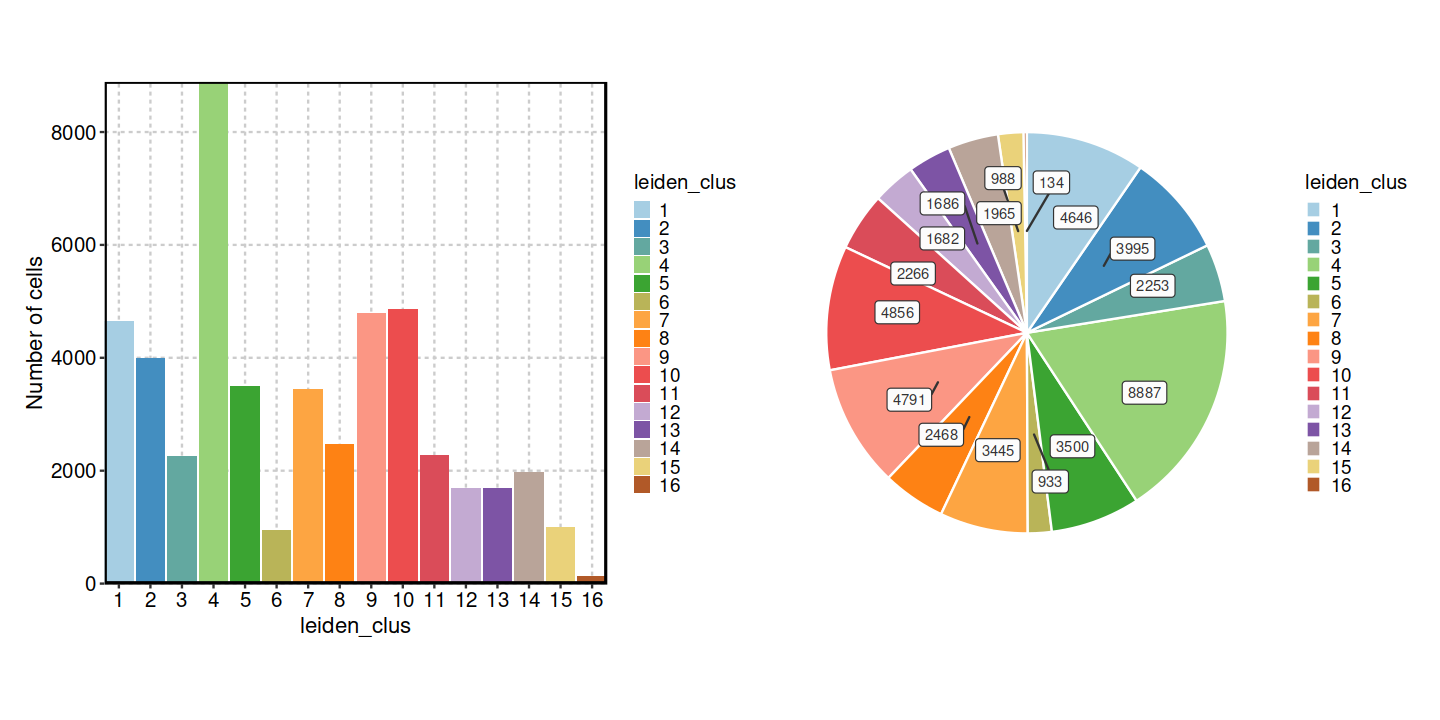

In [6]:
options(repr.plot.width = 12, repr.plot.height = 6)

p1 <- CellStatPlot(pancreas, ident = "leiden_clus")
p2 <- CellStatPlot(pancreas, ident = "leiden_clus", plot_type = "pie")
p1 + p2


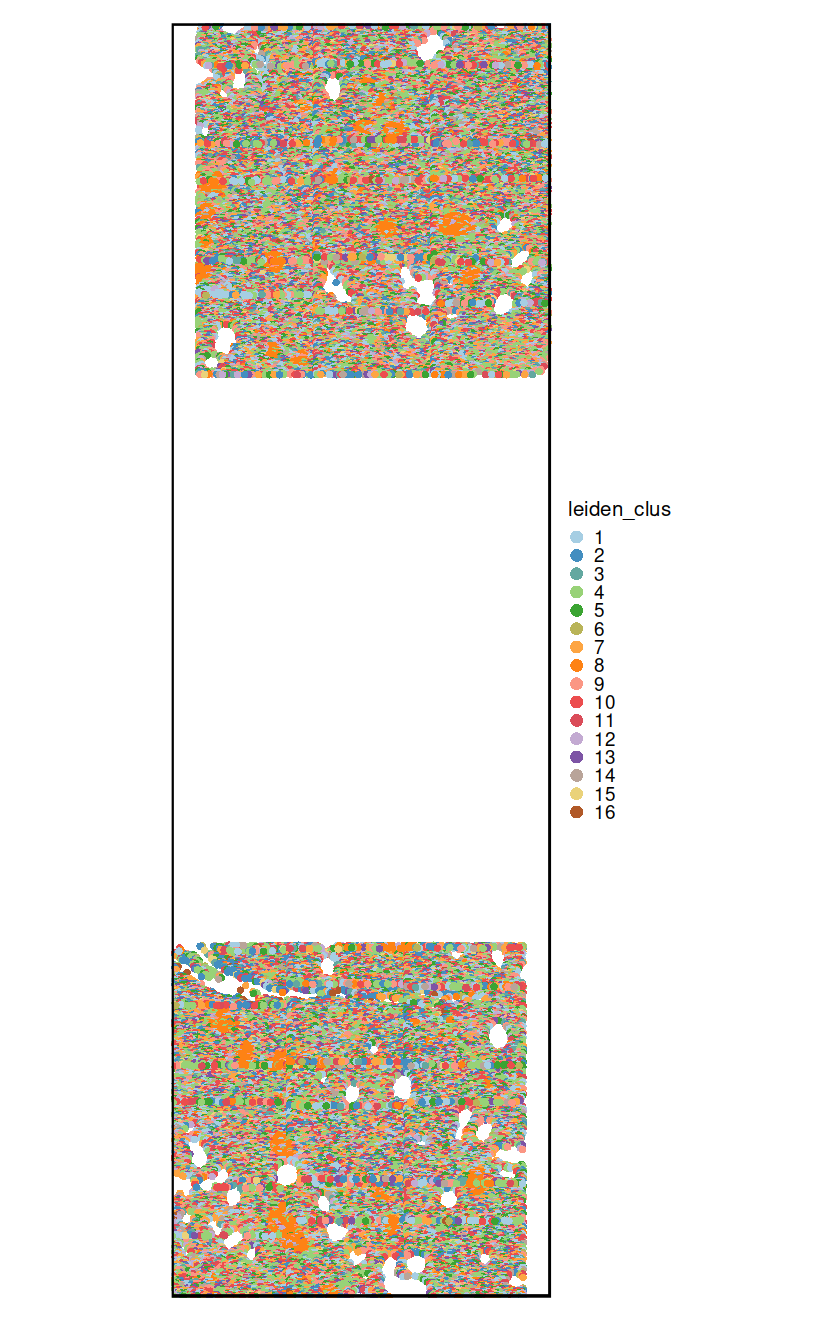

In [7]:
options(repr.plot.width = 7, repr.plot.height = 11)

## every cell in the composited frame, coloured by cluster
SpatDimPlot(
    pancreas,
    group_by = "leiden_clus",
    feat_type = "rna",
    spat_loc_name = "raw",
    ## scplotter's points branch does not set x/y, and this export carries a metadata
    ## column named X (the CosMx run id, constant 1) that plotthis would otherwise bind.
    points_x = "sdimx",
    points_y = "sdimy",
    crop = FALSE
)

markers plotted: CPA1, GCG, INS, KRT19, PRSS1, SST 


Warning message in asMethod(object):
“sparse->dense coercion: allocating vector of size 6.9 GiB”


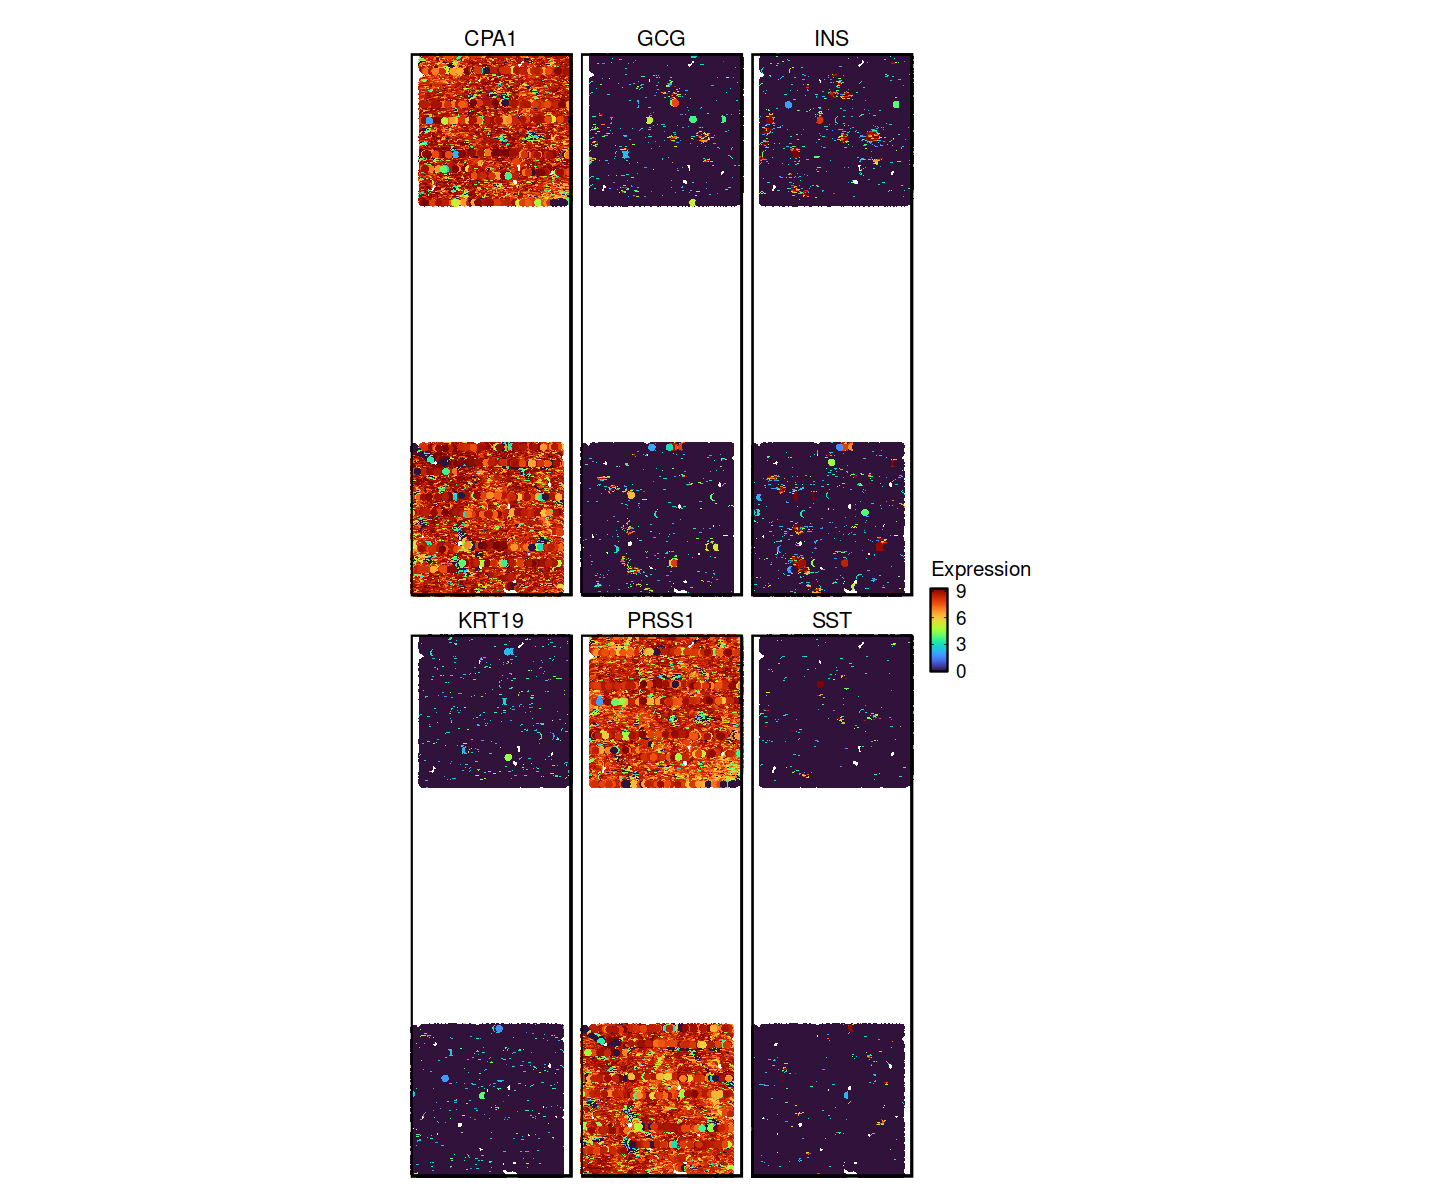

In [8]:
options(repr.plot.width = 12, repr.plot.height = 10)

## Keep only markers this panel detects in a useful number of cells: an undetected feature
## gives an empty facet, and the facetted plot then fails to build a viewport.
fd <- fDataDT(pancreas)
pancreas_markers <- intersect(c("INS", "GCG", "SST", "KRT19", "CPA1", "PRSS1"), fd$feat_ID)
if ("nr_cells" %in% names(fd)) {
    pancreas_markers <- fd[feat_ID %in% pancreas_markers & nr_cells > 50, feat_ID]
}
cat("markers plotted:", paste(pancreas_markers, collapse = ", "), "\n")

## shapes = FALSE keeps this cheap: the export carries ~9.5 million cell polygons, and
## drawing them once per marker facet is what makes the plot run out of memory.
SpatFeaturePlot(
    pancreas,
    features = pancreas_markers,
    feat_type = "rna",
    spat_loc_name = "raw",
    ## scplotter's points branch does not set x/y, and this export carries a metadata
    ## column named X (the CosMx run id, constant 1) that plotthis would otherwise bind.
    points_x = "sdimx",
    points_y = "sdimy",
    crop = FALSE,
    points = TRUE,
    shapes = FALSE
)

### Replicating the upstream vignette with scplotter

Giotto Suite publishes a walkthrough for this dataset:
[Whole transcriptome CosMx Human Pancreas FFPE](https://giottosuite.com/articles/cosmx_pancreas.html).
The cells below reproduce its figures **using scplotter**, so the analysis plots here can be
compared directly with the upstream ones.

Where each figure comes from:

- **Embeddings** (`CellDimPlot`) read the object's own reductions. The reduction names are stored
  lowercase (`pca`, `umap`, `tsne`), and `feat_type = "rna"` must be given explicitly because this
  object also carries a `SystemControl` feature type.
- **Spatial views** call `SpatDimPlot()` / `SpatFeaturePlot()` on the object, with
  `spat_loc_name = "raw"` (this export stores its locations under that name), `crop = FALSE`
  and explicit `points_x = "sdimx"` / `points_y = "sdimy"`. The crop is needed because the
  images carry per-FOV local extents while the cells sit in a global frame, and the explicit
  columns because scplotter does not set x/y for Giotto objects while this export has a
  metadata column named `X` (the run id, constant 1) that would otherwise be bound.
- **Marker expression in embedding space** uses `FeatureStatPlot(plot_type = "dim")`, which
  colours a reduction by feature values and facets one panel per feature.

Not reproduced: the subcellular figures (`spatInSituPlotPoints`, the polygon-fill maps and the
small-subset views). Those need the transcript table, a 4.9 GB export; this notebook loads the
pre-aggregated matrix (`load_expression = TRUE`, `load_transcripts = FALSE`).

One honest difference: the vignette derives PCA from **pearson residuals**
(`calculateHVF(method = "var_p_resid")` on the `pearson` matrix), while this notebook uses
log-normalised values with `calculateHVF()`'s default. The embeddings below are therefore this
notebook's, and the cluster numbering will not match the vignette's.

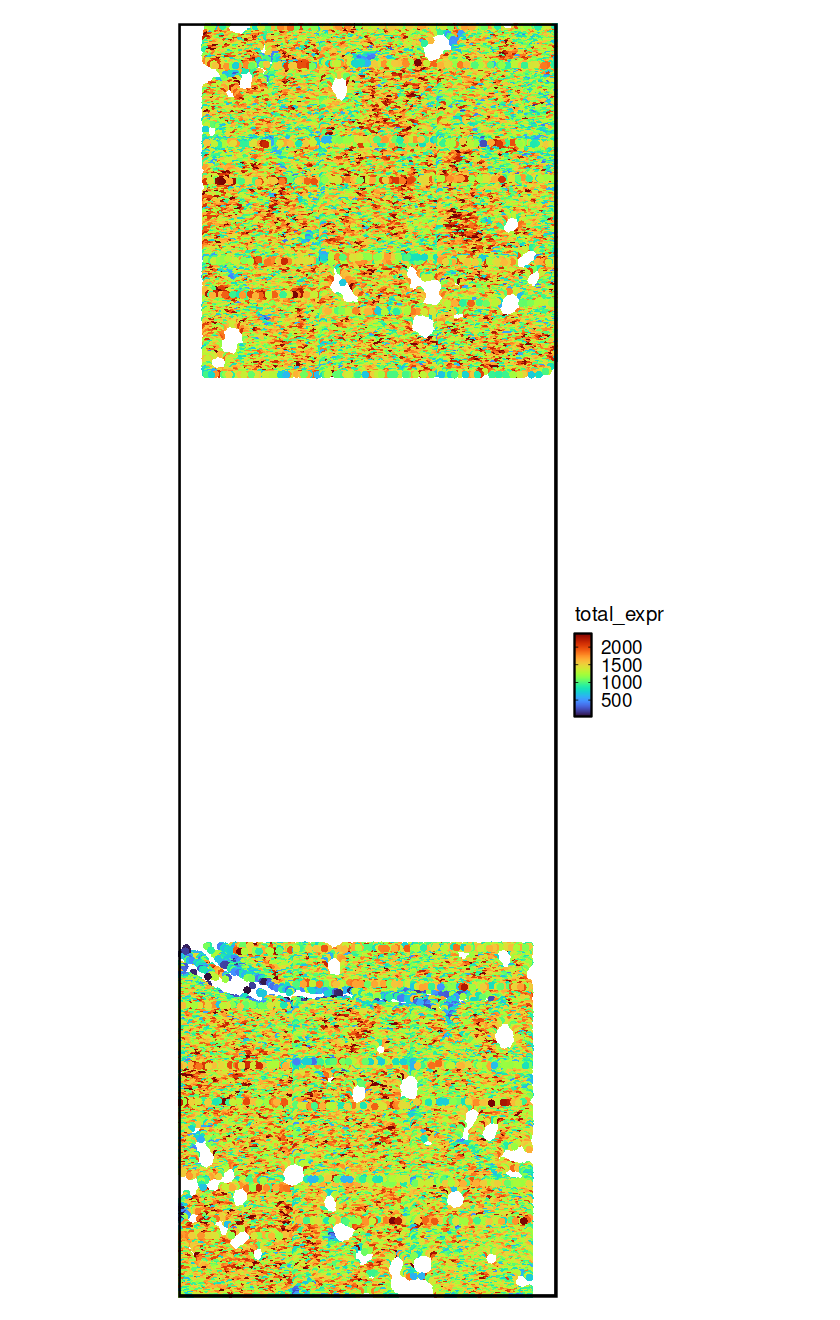

In [9]:
options(repr.plot.width = 7, repr.plot.height = 11)

## Vignette section 10.2 - normalised total expression across the tissue
SpatFeaturePlot(
    pancreas,
    features = "total_expr",
    feat_type = "rna",
    spat_loc_name = "raw",
    ## scplotter's points branch does not set x/y, and this export carries a metadata
    ## column named X (the CosMx run id, constant 1) that plotthis would otherwise bind.
    points_x = "sdimx",
    points_y = "sdimy",
    crop = FALSE,
    points = TRUE,
    shapes = FALSE
)

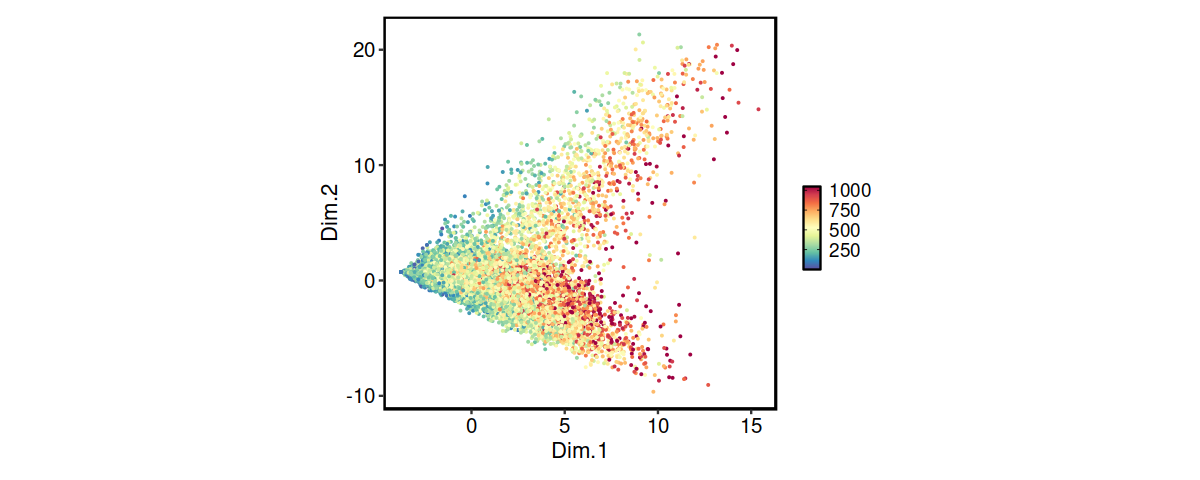

In [10]:
options(repr.plot.width = 10, repr.plot.height = 4)

## Vignette section 11.1 - cells in PCA space, coloured by number of detected features.
## nr_feats is continuous, and CellDimPlot's group_by is for factors, so this goes through
## FeatureStatPlot(plot_type = "dim").
FeatureStatPlot(
    pancreas,
    features = "nr_feats",
    plot_type = "dim",
    reduction = "pca",
    feat_type = "rna"
)

In [11]:
## Vignette section 11.2 - tSNE on the first ten PCs, as in the vignette.
## check_duplicates = FALSE: on a targeted panel many cells share identical PC coordinates, and
## Rtsne otherwise aborts with "Remove duplicates before running TSNE".
pancreas <- runtSNE(pancreas, dimensions_to_use = 1:10, check_duplicates = FALSE)

Setting dimension reduction [cell][rna] tsne



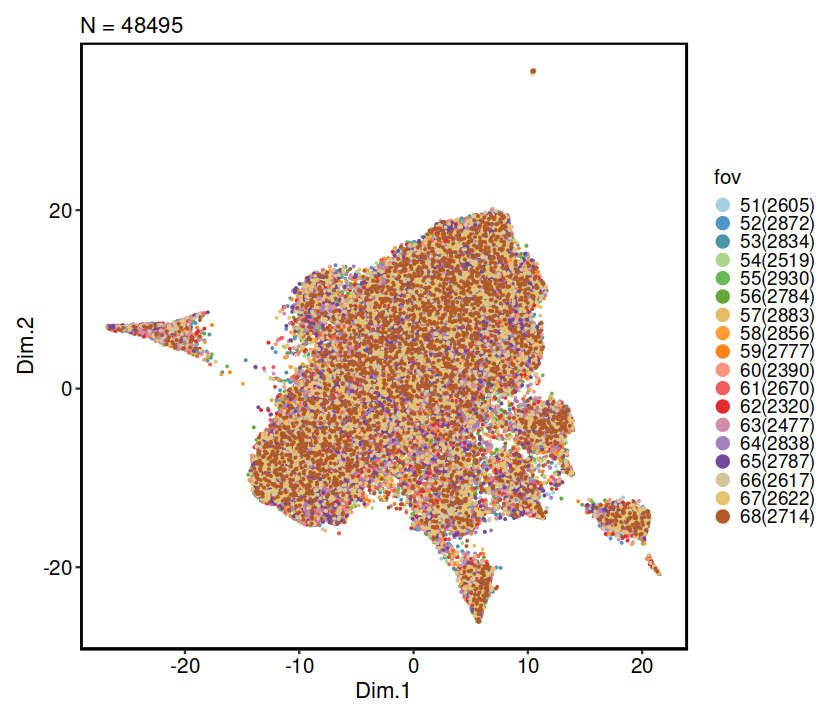

In [12]:
options(repr.plot.width = 7, repr.plot.height = 6)

## Vignette section 11.2 - UMAP coloured by FOV: the two 3x3 imaging blocks separate cleanly
CellDimPlot(pancreas, reduction = "umap", group_by = "fov", feat_type = "rna")

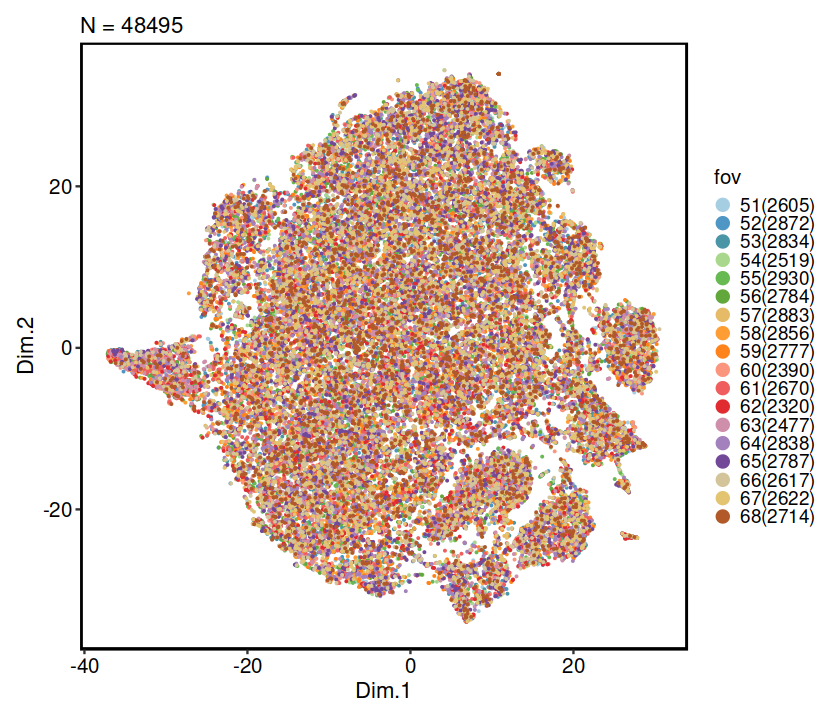

In [13]:
options(repr.plot.width = 7, repr.plot.height = 6)

## Vignette section 11.2 - the same cells in tSNE space
CellDimPlot(pancreas, reduction = "tsne", group_by = "fov", feat_type = "rna")

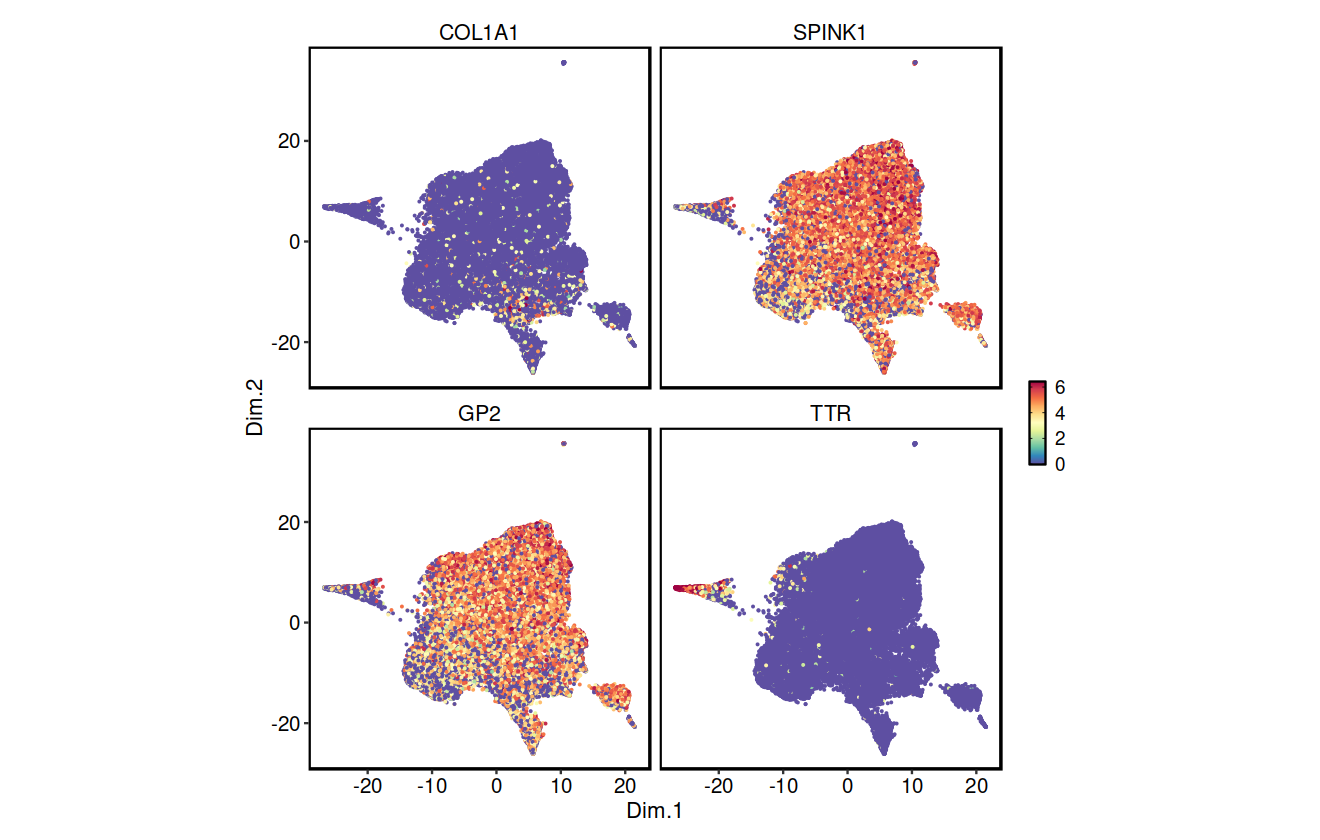

In [14]:
options(repr.plot.width = 11, repr.plot.height = 7)

## Vignette section 11.3 - marker expression in UMAP space. FeatureStatPlot with
## plot_type = "dim" colours a reduction by feature values and facets one panel per feature.
FeatureStatPlot(
    pancreas,
    features = c("COL1A1", "SPINK1", "GP2", "TTR"),
    plot_type = "dim",
    reduction = "umap",
    feat_type = "rna"
)

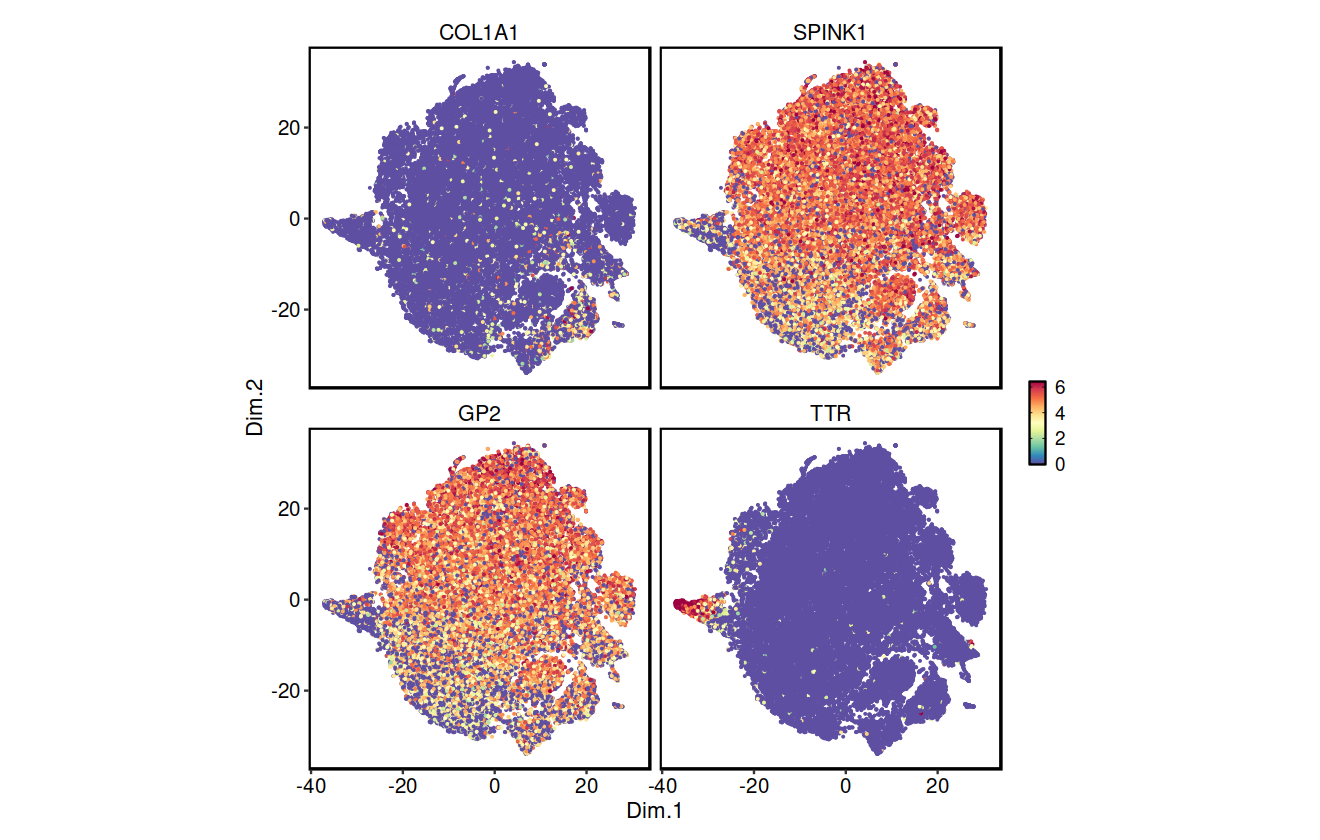

In [15]:
options(repr.plot.width = 11, repr.plot.height = 7)

## Vignette section 11.3 - the same markers in tSNE space
FeatureStatPlot(
    pancreas,
    features = c("COL1A1", "SPINK1", "GP2", "TTR"),
    plot_type = "dim",
    reduction = "tsne",
    feat_type = "rna"
)

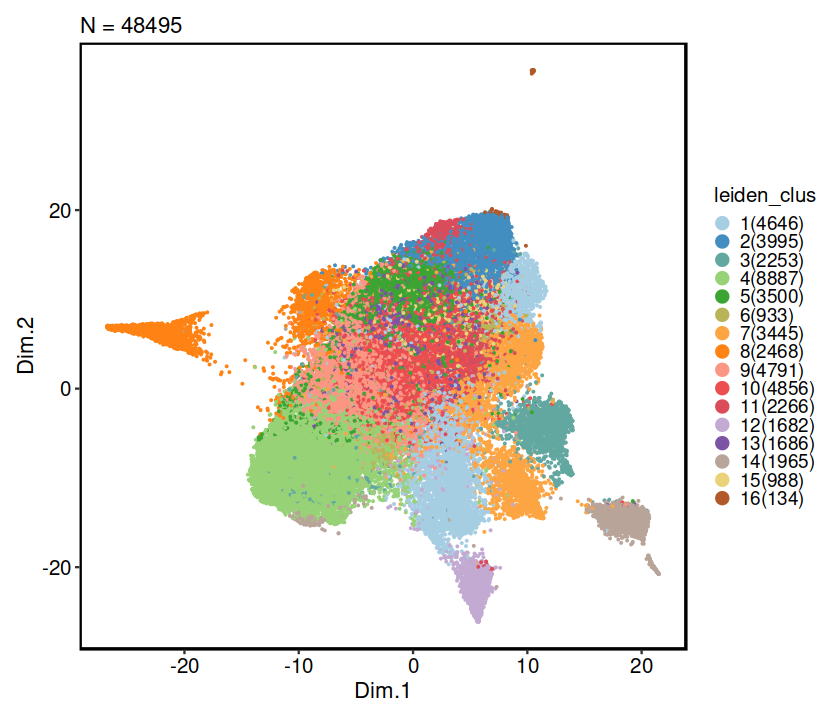

In [16]:
options(repr.plot.width = 7, repr.plot.height = 6)

## Vignette section 12.1 - clusters in UMAP space
CellDimPlot(pancreas, reduction = "umap", group_by = "leiden_clus", feat_type = "rna")

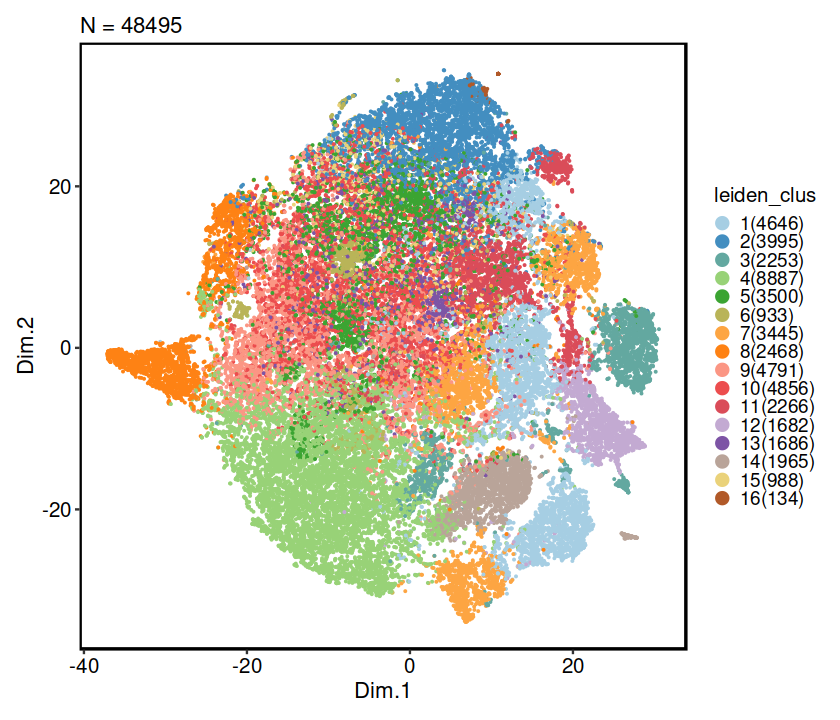

In [17]:
options(repr.plot.width = 7, repr.plot.height = 6)

## Vignette section 12.1 - the same clusters in tSNE space
CellDimPlot(pancreas, reduction = "tsne", group_by = "leiden_clus", feat_type = "rna")

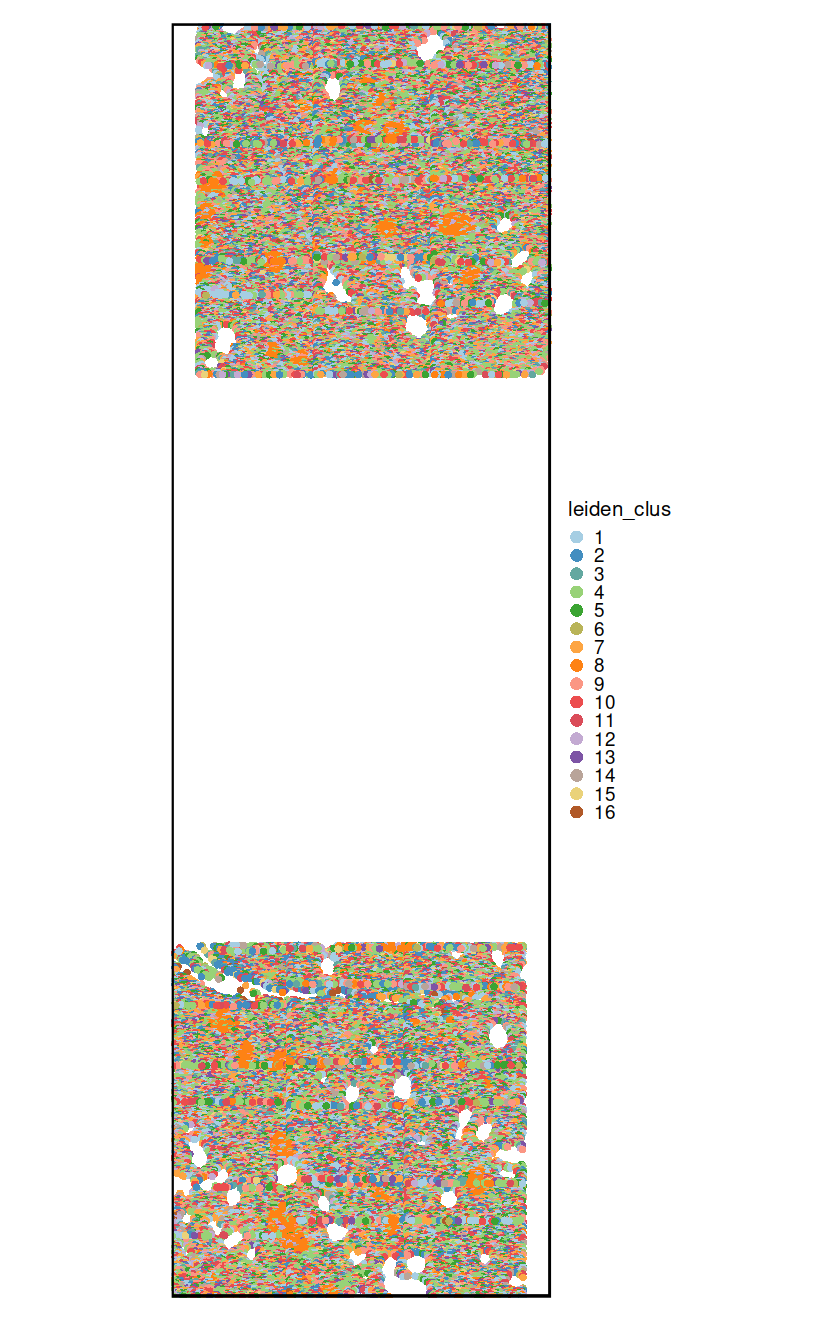

In [18]:
options(repr.plot.width = 7, repr.plot.height = 11)

## Vignette section 12.2 - clusters across the tissue, as points
SpatDimPlot(
    pancreas,
    group_by = "leiden_clus",
    feat_type = "rna",
    spat_loc_name = "raw",
    ## scplotter's points branch does not set x/y, and this export carries a metadata
    ## column named X (the CosMx run id, constant 1) that plotthis would otherwise bind.
    points_x = "sdimx",
    points_y = "sdimy",
    crop = FALSE
)

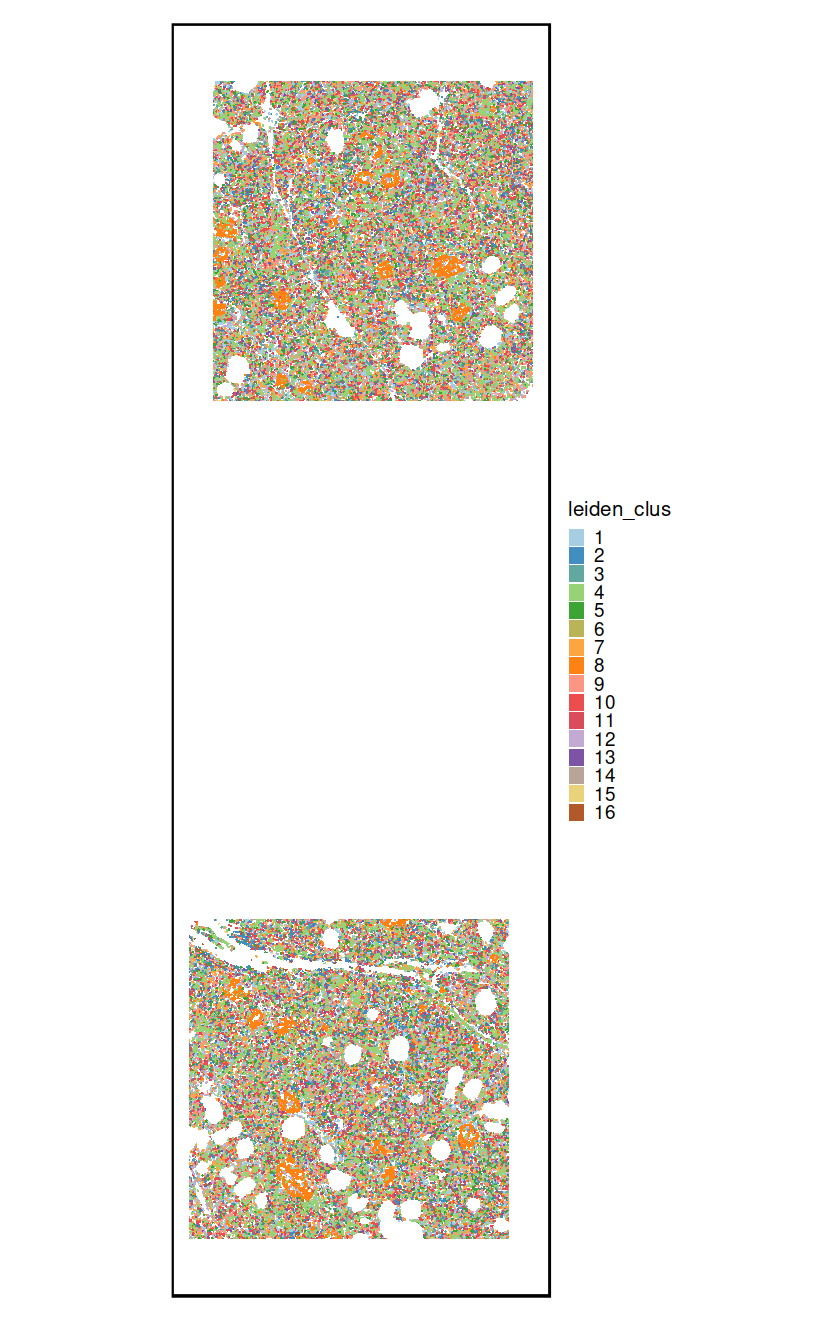

In [19]:
options(repr.plot.width = 7, repr.plot.height = 11)

## Vignette section 12.3 - the same clusters as filled cell polygons. The shape layer does not
## suffer the extent problem the points layer has, so it is drawn straight from the object.
## shapes_border_color = NA is required at this scale: the export has ~9.5 million polygons over
## 7 x 11 inches, so each cell is a fraction of a pixel and the per-polygon outline otherwise
## covers the fill, rendering the whole map black even though the fill is mapped correctly.
SpatDimPlot(
    pancreas,
    group_by = "leiden_clus",
    feat_type = "rna",
    spat_loc_name = "raw",
    points = FALSE,
    shapes = TRUE,
    shapes_fill_by = "leiden_clus",
    shapes_border_color = NA
)